# Two Tank — SD-DPC workflow

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SOLARIS-JHU/SD-DPC/blob/main/case_studies/TwoTank/notebooks/00_colab_workflow.ipynb)


## For Colab, run this cell.


In [ ]:
import sys
!if [ -d /content/SD-DPC/.git ]; then echo "[1/3] Using existing checkout: /content/SD-DPC"; else echo "[1/3] Cloning SD-DPC..."; git clone --depth 1 --progress https://github.com/SOLARIS-JHU/SD-DPC.git /content/SD-DPC; fi
%cd /content/SD-DPC

# Neuromancer 1.5.3 pins NumPy 1.26, which has no Python 3.13 wheel.
# Keep Colab's compatible NumPy, pandas, and PyTorch, and install the remaining runtime packages.
print('[2/3] Installing Colab-compatible runtime dependencies...')
%pip install --progress-bar on --no-deps neuromancer==1.5.3
%pip install --progress-bar on dill graphviz mlflow "networkx==3.0.0" "plum-dispatch==1.7.3" scikit-learn scipy six "pydot==1.4.2" pyts torchdiffeq toml lightning cvxpy "casadi>=3.7.0" wandb torchsde PyYAML seaborn

print('[3/3] Installing SD-DPC in editable mode...')
%pip install --progress-bar on --no-deps -e .

# Legacy editable installs may require exposing src/ to the current Colab kernel explicitly.
src_dir = '/content/SD-DPC/src'
if src_dir not in sys.path:
    sys.path.insert(0, src_dir)

import casadi
import neuromancer
import sdpc
import torch
print(f'Ready: SD-DPC | Python {sys.version.split()[0]} | PyTorch {torch.__version__} | Neuromancer {neuromancer.__version__}')


## Workflow options

The default configuration uses the pretrained system-identification and sparse-policy checkpoints, so the complete analysis can run without retraining. Set either training switch below to `True` to retrain that stage with the case YAML configuration. A newly trained system model is passed directly to policy training, and a newly trained policy is passed to evaluation.

Each stage begins with only the inputs it uses. Section 1 controls system-identification training; Section 2 controls policy training and the nominal rollout; Section 3 controls the evaluation scenario count and controller methods. The 2-D integrator rollout also exposes every ellipse parameter.

### Case study dynamics

The states are the two liquid levels and the inputs are the pump command and flow split,

$$
\dot{x}_1=c_1(1-u_2)u_1-c_2\sqrt{x_1},\qquad
\dot{x}_2=c_1u_2u_1+c_2\sqrt{x_1}-c_2\sqrt{x_2},
$$

with $c_1=0.08$ and $c_2=0.04$. The controller tracks a common level reference while respecting $x_i,u_i\in[0,1]$; the sample time is $\Delta t=1$.



In [1]:
from pathlib import Path
import copy
import sys
import warnings
warnings.filterwarnings('ignore')

def find_repo_root(start=Path.cwd()):
    # This works in both a cloned Colab checkout and a local repository.
    for candidate in (start, *start.parents):
        if (candidate / 'src' / 'sdpc').is_dir() and (candidate / 'case_studies').is_dir():
            return candidate
    raise FileNotFoundError('Run this notebook from inside the SD-DPC repository')

REPO_ROOT = find_repo_root()
CASE_DIR = REPO_ROOT / 'case_studies' / 'TwoTank'
CONFIGS = CASE_DIR / 'configs'
CHECKPOINTS = CASE_DIR / 'checkpoints'
RESULTS = CASE_DIR / 'results'
sys.path.insert(0, str(REPO_ROOT / 'src'))

import matplotlib as mpl
import torch
from sdpc.config import load_config
from sdpc.registry import make_system

SYSTEM = 'twotank'
device = torch.device('cpu')
system = make_system(SYSTEM, device=device)
sysid_cfg = load_config(CONFIGS / 'sysid.yaml')
policy_cfg = load_config(CONFIGS / 'policy.yaml')
eval_cfg = load_config(CONFIGS / 'eval_nominal.yaml')

# Consistent notebook styling with high-resolution inline and saved figures.
mpl.rcParams.update({
    'figure.dpi': 160, 'savefig.dpi': 400,
    'font.family': 'serif', 'font.serif': ['Times New Roman', 'Times', 'DejaVu Serif'],
    'mathtext.fontset': 'stix', 'axes.titlepad': 10,
})

def output_section(title):
    # Give every long-running stage an unmistakable boundary in Colab output.
    print('\n' + '─' * 78)
    print(title)
    print('─' * 78 + '\n')

print('Ready:', SYSTEM, '| case configurations loaded')


Ready: twotank | case configurations loaded


## 1. Sparse system identification

The dynamics are represented by a prescribed dictionary of candidate functions,

$$
\hat{x}_{k+1}=F_{\Xi_f}(x_k,u_k)=\Theta_f(x_k,u_k)\,\Xi_f.
$$

Training minimizes one-step and rollout prediction errors together with an $\ell_1$ penalty on $\Xi_f$. Sequential thresholding removes coefficients below $\tau$; the optional debias phase then fixes the surviving support, sets the sparsity penalty to zero, and refits only those coefficients.

With `TRAIN_SYSTEM_ID = False`, this section loads the pretrained dynamics checkpoint. With `True`, it trains from `sysid.yaml`, saves a numbered run, and passes the resulting model directly to policy learning. The plot compares the selected model with a held-out true trajectory.



──────────────────────────────────────────────────────────────────────────────
1 · SYSTEM IDENTIFICATION
──────────────────────────────────────────────────────────────────────────────

System ID: pretrained checkpoint
Dynamics source: /Users/alireza/Documents/PythonProject/SD-DPC/case_studies/TwoTank/checkpoints/dynamics_sindy.pt
Active terms per state: [3, 3]
dx0/dt = +7.9942e-02·u0 + -3.9976e-02·sqrt(x0) + -7.9905e-02·u0*u1
dx1/dt = +3.9981e-02·sqrt(x0) + -3.9980e-02·sqrt(x1) + +7.9943e-02·u0*u1
Held-out rollout MSE: 3.488e-11


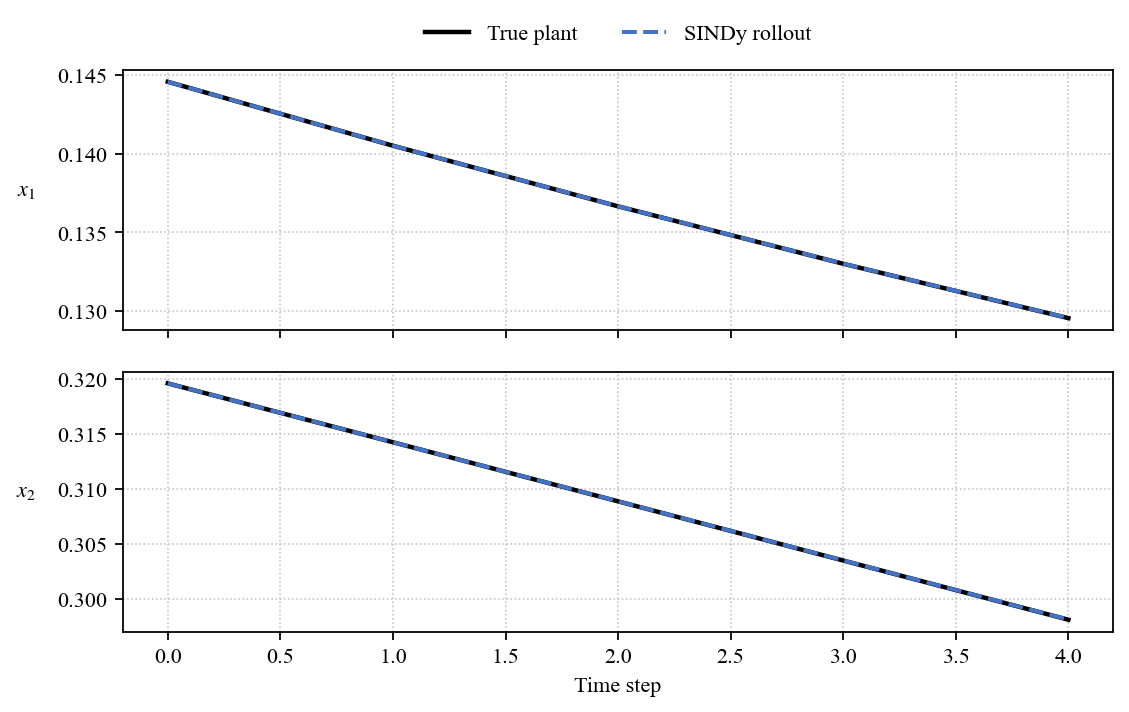

In [2]:
# ---- Section 1 inputs ---------------------------------------------------
TRAIN_SYSTEM_ID = False  # True: fit and save a new SINDy dynamics model.

output_section('1 · SYSTEM IDENTIFICATION')

print('System ID:', 'train' if TRAIN_SYSTEM_ID else 'pretrained checkpoint')

from sdpc.io import CustomLogger, new_run_dir, snapshot_config
from sdpc.plotting import plot_coef_heatmap
from sdpc.sindy import CompiledFunctionLibrary, SINDyVectorized, load_model, save_model
from sdpc.training import make_debias_config, train_sysid
import matplotlib.pyplot as plt

if TRAIN_SYSTEM_ID:
    # Build the configured dictionary and optimize all candidate coefficients.
    library = CompiledFunctionLibrary(**system.sindy_library_cfg())
    sindy = SINDyVectorized(library=library, n_out=system.nx, device=device)
    train_loader, dev_loader, test_data = system.make_sysid_data(sysid_cfg, device)
    logger = CustomLogger(
        args={'stage': 'system_id'}, savedir=str(RESULTS / 'logs' / 'sysid_colab'),
        verbosity=sysid_cfg.get('verbosity', max(1, sysid_cfg['epochs'] // 10)),
        stdout=['train_loss', 'dev_loss'],
    )
    train_sysid(system, sindy, train_loader, dev_loader, sysid_cfg, device, logger=logger)

    # Debias refits the coefficients while preserving the pruned support exactly.
    if sysid_cfg.get('debias', {}).get('enabled', False):
        support = [list(indices) for indices in sindy.active_idx]
        debias_cfg = make_debias_config(sysid_cfg)
        train_sysid(system, sindy, train_loader, dev_loader, debias_cfg, device, logger=logger)
        assert [list(indices) for indices in sindy.active_idx] == support

    dynamics_run = new_run_dir(RESULTS / 'models' / 'dynamics')
    dynamics_path = dynamics_run / 'saved_models' / 'sindy.pt'
    save_model(sindy, dynamics_path)
    snapshot_config(dynamics_run, sysid_cfg)
else:
    # Load the included pretrained dynamics model.
    dynamics_path = CHECKPOINTS / 'dynamics_sindy.pt'
    sindy = load_model(dynamics_path, device=device)
    _, _, test_data = system.make_sysid_data(sysid_cfg, device)

print('Dynamics source:', dynamics_path)
print('Active terms per state:', [len(indices) for indices in sindy.active_idx])
sindy.pretty_print()

# Compare a recursive model rollout with an unseen true-system trajectory.
step = system.discrete_step(sindy)
X_true, U_test = test_data['X'][0], test_data['u'][0]
x, prediction = X_true[:1], [X_true[:1]]
with torch.no_grad():
    for k in range(len(U_test) - 1):
        x = step(x, U_test[k:k + 1])
        prediction.append(x)
prediction = torch.cat(prediction).detach().cpu().numpy()
truth = X_true.detach().cpu().numpy()
print(f'Held-out rollout MSE: {((prediction - truth) ** 2).mean():.3e}')

fig, axes = plt.subplots(system.nx, 1, figsize=(7.2, 2.25 * system.nx), sharex=True)
axes = axes if system.nx > 1 else [axes]
for i, ax in enumerate(axes):
    ax.plot(truth[:, i], color='black', lw=2.0, label='True plant')
    ax.plot(prediction[:, i], '--', color='#4472C4', lw=1.8, label='SINDy rollout')
    ax.set_ylabel(rf'$x_{{{i + 1}}}$', rotation=0, labelpad=14)
    ax.grid(color='0.75', linestyle=':', linewidth=0.7)
axes[0].legend(frameon=False, ncol=2, loc='lower center', bbox_to_anchor=(0.5, 1.02))
axes[-1].set_xlabel('Time step')
fig.subplots_adjust(left=0.12, right=0.98, bottom=0.12, top=0.90, hspace=0.16)
plt.show()


## 2. Sparse policy learning

The controller uses a second dictionary and projects its output onto the admissible input set,

$$
u_k=\pi_{\Xi_\pi}(x_k,r_k)
=\Pi_{\mathcal U}\!\left(\Theta_\pi(x_k,r_k)\,\Xi_\pi\right).
$$

The coefficients are optimized through a differentiable closed-loop rollout of the selected dynamics model. The objective combines tracking, control effort, constraint penalties, and $\ell_1$ regularization. Sequential thresholding and fixed-support debiasing produce a compact symbolic controller.

With `TRAIN_POLICY = False`, this section loads the pretrained sparse-policy checkpoint. With `True`, it trains from `policy.yaml` using the dynamics selected above and saves a numbered run. The coefficient heatmap and nominal rollout inspect the selected policy. For the nominal rollout, `ROLLOUT_REFERENCE` accepts either one scalar setpoint or an ordered list of scalar setpoints. Each scalar is applied to both $x_1$ and $x_2$, and a list is distributed as evenly as possible across `ROLLOUT_STEPS`.



──────────────────────────────────────────────────────────────────────────────
2 · SPARSE POLICY LEARNING
──────────────────────────────────────────────────────────────────────────────

Policy: pretrained checkpoint
Rollout: x0=[0.7, 0.5], reference sequence=[0.25, 0.75, 0.35, 0.65], steps=1000
Policy source: /Users/alireza/Documents/PythonProject/SD-DPC/case_studies/TwoTank/checkpoints/policy_sparse.pt
Active terms per output: [4, 2]
Total active terms: 6
u0 = +6.1979e-01·r0 + +1.4659e+00·cos(2·x0) + +2.1415e+00·cos(2·x1) + -3.4944e+00·cos(2·r0)
u1 = -4.2401e+00·cos(2·x0) + +4.2429e+00·cos(2·x1)


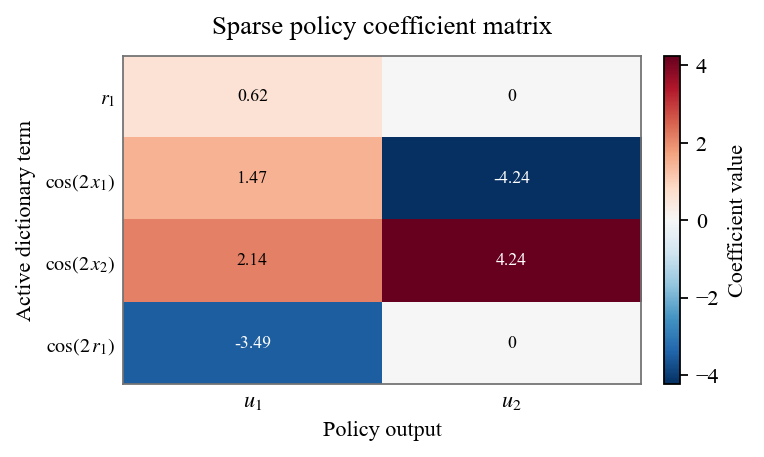

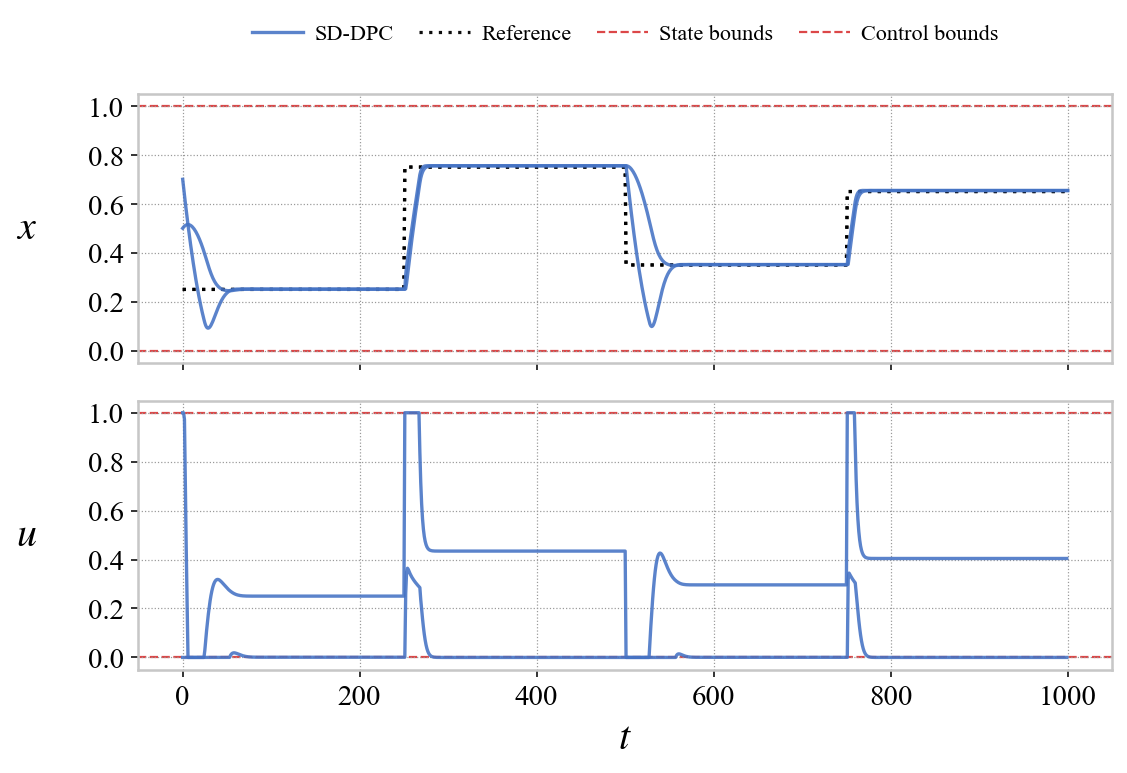

Initial state: [0.699999988079071, 0.5] | final state: [0.6540687680244446, 0.6541571617126465]


In [3]:
# ---- Section 2 inputs ---------------------------------------------------
TRAIN_POLICY = False  # True: train against the dynamics selected in Section 1.
ROLLOUT_X0 = [0.70, 0.50]  # One value per state.
# One scalar or an ordered list; every scalar is used for both x1 and x2.
ROLLOUT_REFERENCE = [0.25, 0.75, 0.35, 0.65]
ROLLOUT_STEPS = 1000

if len(ROLLOUT_X0) != system.nx:
    raise ValueError(f'ROLLOUT_X0 must contain {system.nx} values')
if ROLLOUT_STEPS < 1:
    raise ValueError('ROLLOUT_STEPS must be positive')
if isinstance(ROLLOUT_REFERENCE, (int, float)):
    rollout_reference_levels = [float(ROLLOUT_REFERENCE)]
else:
    rollout_reference_levels = [float(value) for value in ROLLOUT_REFERENCE]
if not rollout_reference_levels or len(rollout_reference_levels) > ROLLOUT_STEPS:
    raise ValueError('ROLLOUT_REFERENCE must contain between 1 and ROLLOUT_STEPS scalar values')
if any(not system.xmin <= value <= system.xmax for value in rollout_reference_levels):
    raise ValueError(f'ROLLOUT_REFERENCE values must lie inside [{system.xmin}, {system.xmax}]')

output_section('2 · SPARSE POLICY LEARNING')

print('Policy:', 'train' if TRAIN_POLICY else 'pretrained checkpoint')
print(f'Rollout: x0={ROLLOUT_X0}, reference sequence={rollout_reference_levels}, steps={ROLLOUT_STEPS}')

from sdpc.io import new_policy_run_dir
from sdpc.training import train_policy

if TRAIN_POLICY:
    # Optimize a symbolic policy through the differentiable identified dynamics.
    policy_library = CompiledFunctionLibrary(**system.policy_library_cfg())
    policy = SINDyVectorized(
        library=policy_library, n_out=system.nu,
        policy_name=[f'u{i}' for i in range(system.nu)],
        device=device, seed=policy_cfg.get('policy_seed', 0),
    )
    if policy_cfg.get('init_scale') is not None:
        for coefficient in policy.Xi:
            coefficient.data.mul_(policy_cfg['init_scale'])

    train_loader, dev_loader = system.make_policy_data(policy_cfg, device)
    logger = CustomLogger(
        args={'stage': 'policy'}, savedir=str(RESULTS / 'logs' / 'policy_colab'),
        verbosity=policy_cfg['verbosity'],
        stdout=policy_cfg.get('logger_metrics', ['train_loss', 'dev_loss']),
    )
    train_policy(
        system, sindy, policy, train_loader, dev_loader, policy_cfg, device,
        logger=logger, action_scale=policy_cfg.get('action_scale', 1.0),
    )

    # Keep the selected symbolic support fixed during the debias phase.
    if policy_cfg.get('debias', {}).get('enabled', False):
        support = [list(indices) for indices in policy.active_idx]
        debias_cfg = make_debias_config(policy_cfg)
        train_policy(
            system, sindy, policy, train_loader, dev_loader, debias_cfg, device,
            logger=logger, action_scale=policy_cfg.get('action_scale', 1.0),
        )
        assert [list(indices) for indices in policy.active_idx] == support

    policy_run = new_policy_run_dir(RESULTS, 'sparse')
    policy_path = policy_run / 'saved_models' / 'policy_sparse.pt'
    save_model(policy, policy_path)
    snapshot_config(policy_run, policy_cfg)
else:
    policy_path = CHECKPOINTS / 'policy_sparse.pt'
    policy = load_model(policy_path, device=device)

policy.eval()
print('Policy source:', policy_path)
print('Active terms per output:', [len(indices) for indices in policy.active_idx])
print('Total active terms:', sum(len(indices) for indices in policy.active_idx))
policy.pretty_print()

# The annotated matrix shows the exact retained symbolic policy parameters.
plot_coef_heatmap(policy, title='Sparse policy coefficient matrix', annotate=True)
plt.show()

from sdpc.data import make_equal_piecewise_reference
from sdpc.eval import make_test_data, rollout_closed_loop
nominal_plant = system.discrete_step(sindy)
rollout_reference = make_equal_piecewise_reference(
    system.nx, ROLLOUT_STEPS, rollout_reference_levels, device=device,
)
data = make_test_data(
    system.nx, ROLLOUT_STEPS, ROLLOUT_X0, rollout_reference[0], device=device,
)
result = rollout_closed_loop(
    policy, nominal_plant, data, umin=system.umin, umax=system.umax,
    action_scale=policy_cfg.get('action_scale', 1.0),
)
from sdpc.plotting import plot_states_and_controls

# Leave the title to the notebook heading and place one clean legend above the axes.
plot_states_and_controls(
    [{'x': result['x_traj'], 'u': result['u_traj'], 'label': 'SD-DPC', 'color': '#4472C4'}],
    r_traj=data['r'], xmin=system.xmin, xmax=system.xmax,
    umin=system.umin, umax=system.umax, title='', legend_ncol=4,
    legend_bbox=(0.5, 1.12), figsize=(7.2, 5.0), use_tex=False,
)
plt.show()
print('Initial state:', data['xn'][0, 0].tolist(), '| final state:', result['x_traj'][0, -1].tolist())


## 3. Closed-loop evaluation

Evaluation applies each selected controller to the same true-plant scenarios. Set `EVAL_STEPS` to the total number of closed-loop time steps. Enter the ordered scalar setpoints in `EVAL_REFERENCE_LEVELS`; the reference changes through the trajectory in that order, and every value is applied to both tank states, so $r_1=r_2$. Each value is held for a segment of the horizon, with the selected steps divided among the segments as evenly as possible.

Set `EVAL_SCENARIOS` to the Monte Carlo sample count, and use `EVAL_INITIAL_STATE` to apply the same fixed start in every scenario. Leave `EVAL_INITIAL_STATE = None` for a different seeded start in every scenario. Select any supported subset in `EVAL_METHODS`: `sd_dpc`, `nn_dpc`, and `mpc`. The YAML defaults are copied before the notebook applies these interactive choices.

The tables report tracking, constraint, control-effort, and timing metrics on matched initial conditions and references. The plotted scenario uses the same data for every selected method, making differences in the closed-loop trajectories directly comparable.



──────────────────────────────────────────────────────────────────────────────
3 · CLOSED-LOOP EVALUATION
──────────────────────────────────────────────────────────────────────────────

Evaluation: 2.0 scenarios, 1000 steps, methods=['sd_dpc', 'nn_dpc', 'mpc']
Reference sequence for both x1 and x2: [0.2, 0.75, 0.35, 0.65]
Initial state: random per scenario
MPC trajectory 1/2
  Solve_Succeeded: horizon=50, mean 2.8 iterations/step, 8.414 s total
MPC trajectory 2/2
  Solve_Succeeded: horizon=50, mean 2.8 iterations/step, 9.538 s total


,batched_rollout_wall_time_s_mean,batched_rollout_wall_time_s_std,control_cost_l1_mean,control_cost_l1_std,control_cost_l2_mean,control_cost_l2_std,control_rate_violation_magnitude_mean,control_rate_violation_magnitude_std,control_smoothness_rms_mean,control_smoothness_rms_std,...,mpc_max_iterations_per_solve_mean,mpc_max_iterations_per_solve_std,mpc_setup_time_s_mean,mpc_setup_time_s_std,mpc_solve_per_step_ms_mean,mpc_solve_per_step_ms_std,mpc_solve_time_s_mean,mpc_solve_time_s_std,mpc_solver_iterations_mean,mpc_solver_iterations_std
sd_dpc,0.303178,0.0,364.906342,3.875336,154.533913,4.714104,0.0,0.0,0.041145,0.001079,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nn_dpc,0.291562,0.0,375.983704,0.614624,151.961685,0.261337,0.0,0.0,0.040151,0.000677,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mpc,NaN,NaN,359.025787,1.714813,148.997574,0.418808,0.0,0.0,0.039471,0.000018,...,47.0,0.0,0.07095,0.006572,8.976122,0.561775,8.976122,0.561775,2798.5,12.5


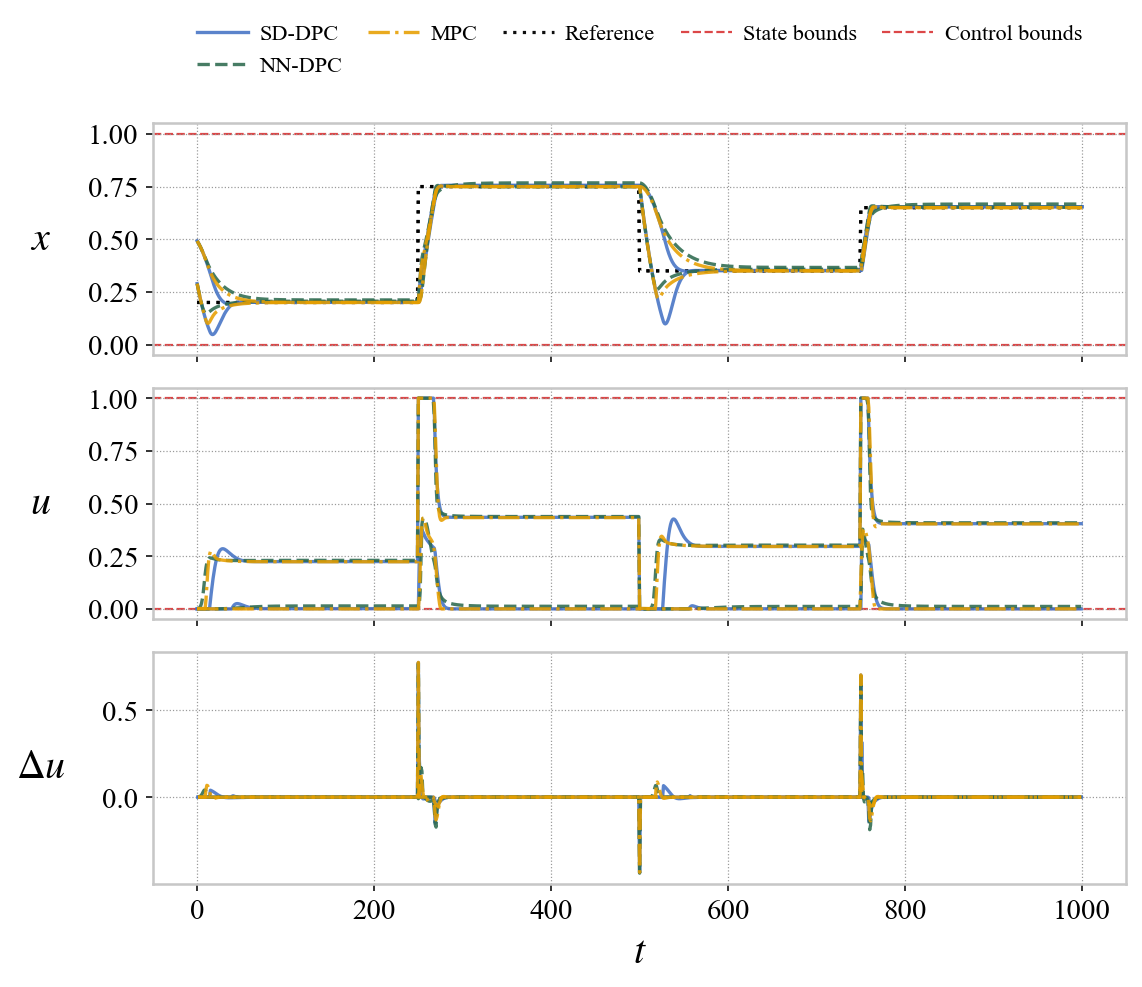

In [4]:
# ---- Section 3 inputs ---------------------------------------------------
EVAL_SCENARIOS = 2.0
EVAL_METHODS = ['sd_dpc', 'nn_dpc', 'mpc']  # Remove any method you do not want to run.
EVAL_INITIAL_STATE = None  # None: random starts; e.g. [0.70, 0.50] for a fixed start.
EVAL_STEPS = int(eval_cfg.get('nsteps', 1000))
# Ordered scalar setpoints. Each one is applied to both x1 and x2.
EVAL_REFERENCE_LEVELS = [0.20, 0.75, 0.35, 0.65]

if EVAL_SCENARIOS < 1:
    raise ValueError('EVAL_SCENARIOS must be at least 1')
if EVAL_STEPS < 1:
    raise ValueError('EVAL_STEPS must be at least 1')
if not EVAL_REFERENCE_LEVELS or len(EVAL_REFERENCE_LEVELS) > EVAL_STEPS:
    raise ValueError('EVAL_REFERENCE_LEVELS must contain between 1 and EVAL_STEPS values')
reference_levels = [float(value) for value in EVAL_REFERENCE_LEVELS]
if not EVAL_METHODS:
    raise ValueError('EVAL_METHODS cannot be empty')
if EVAL_INITIAL_STATE is not None and len(EVAL_INITIAL_STATE) != system.nx:
    raise ValueError(f'EVAL_INITIAL_STATE must contain {system.nx} values')

output_section('3 · CLOSED-LOOP EVALUATION')

print(f'Evaluation: {EVAL_SCENARIOS} scenarios, {EVAL_STEPS} steps, methods={EVAL_METHODS}')
print(f'Reference sequence for both x1 and x2: {reference_levels}')
print('Initial state:', EVAL_INITIAL_STATE if EVAL_INITIAL_STATE is not None else 'random per scenario')

# Copy the YAML configuration before applying the user-selected evaluation controls.
evaluation_cfg = copy.deepcopy(eval_cfg)
evaluation_cfg.pop('seeds', None)
evaluation_cfg['n_trajectories'] = int(EVAL_SCENARIOS)
evaluation_cfg['methods'] = list(EVAL_METHODS)
evaluation_cfg['nsteps'] = int(EVAL_STEPS)
evaluation_cfg['n_references'] = len(reference_levels)
evaluation_cfg['reference'] = {
    'mode': 'sequence',
    'levels': reference_levels,
}
evaluation_cfg['initial_state'] = EVAL_INITIAL_STATE
allowed_methods = {'sd_dpc', 'nn_dpc', 'mpc'}
unknown_methods = sorted(set(EVAL_METHODS) - allowed_methods)
if unknown_methods:
    raise ValueError(f'Unknown methods: {unknown_methods}; choose from {sorted(allowed_methods)}')

from sdpc.io import find_nn_checkpoint
from sdpc.training import load_nn_policy

# Load the neural baseline only when it is part of this comparison.
nn_policy = None
if 'nn_dpc' in EVAL_METHODS:
    nn_path = find_nn_checkpoint(RESULTS, evaluation_cfg)
    nn_policy = load_nn_policy(system, nn_path, evaluation_cfg, device=device)

import pandas as pd
from sdpc.eval import evaluate_twotank_nominal, policy_forward_latency
from sdpc.plotting import plot_states_and_controls

latencies = {}
probe_x = torch.zeros(1, 1, system.nx, device=device)
probe_r = torch.zeros(1, 1, system.nx, device=device)
for name, model in [('sd_dpc', policy), ('nn_dpc', nn_policy)]:
    if name in EVAL_METHODS:
        latencies[name] = policy_forward_latency(
            model, probe_x, probe_r, **evaluation_cfg['inference_benchmark']
        )

out = evaluate_twotank_nominal(
    system, policy, nn_policy, evaluation_cfg, device,
    progress=True, policy_latencies=latencies,
)
display(pd.DataFrame.from_dict(out['summary'], orient='index'))

index = 0
styles = {
    'sd_dpc': ('SD-DPC', '#4472C4', '-'),
    'nn_dpc': ('NN-DPC', '#2D6A4F', '--'),
    'mpc': ('MPC', '#E69F00', '-.'),
}
entries = [
    {
        'x': out['trajectories'][name]['x_traj'][index:index + 1],
        'u': out['trajectories'][name]['u_traj'][index:index + 1],
        'label': styles[name][0], 'color': styles[name][1], 'linestyle': styles[name][2],
    }
    for name in EVAL_METHODS
]
plot_states_and_controls(
    entries, r_traj=out['scenarios']['r'][index:index + 1],
    xmin=system.xmin, xmax=system.xmax, umin=system.umin, umax=system.umax,
    title='', show_control_rate=True, show_legend=True,
    legend_bbox=(0.5, 1.13), legend_ncol=min(5, len(EVAL_METHODS) + 3),
    figsize=(7.2, 6.6), use_tex=False,
)
plt.show()
